# Full-cohort validation experiments

This notebook uses the complete source-family validation cohort. Evidence metrics,
tokenizer retention and answer EM/F1 are separate. Tables and plots are recorded
measurements with exact cohort identities; no test questions are opened here.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from types import SimpleNamespace
from collections import Counter
from dataclasses import dataclass, asdict
from functools import lru_cache
import collections, csv, hashlib, html, io, json, math, random, re, statistics, string, subprocess, sys, time, zipfile
import numpy as np
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, HTML, SVG

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Run in this repository"
FIGURES = ROOT / "assets/plots"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "svg.fonttype": "none",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def sha(raw):
    return hashlib.sha256(raw).hexdigest()


def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))


def table(rows, columns, caption):
    header = "".join("<th>" + html.escape(str(c)) + "</th>" for c in columns)
    body = "".join(
        "<tr>"
        + "".join("<td>" + html.escape(str(r.get(c, ""))) + "</td>" for c in columns)
        + "</tr>"
        for r in rows
    )
    display(
        HTML(
            "<table><caption>"
            + html.escape(caption)
            + "</caption><thead><tr>"
            + header
            + "</tr></thead><tbody>"
            + body
            + "</tbody></table>"
        )
    )


def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name + ".png"), dpi=160)
    fig.savefig(FIGURES / (name + ".svg"))
    svg_path = FIGURES / (name + ".svg")
    svg_path.write_text(
        "\n".join(
            line.rstrip() for line in svg_path.read_text(encoding="utf-8").splitlines()
        )
        + "\n",
        encoding="utf-8",
        newline="\n",
    )
    display(SVG(svg_path.read_text(encoding="utf-8")))
    plt.close(fig)


print("Analysis kernel ready. No model weights loaded.")


Analysis kernel ready. No model weights loaded.


In [2]:
retrieval = read_json("docs/full-validation-retrieval.json")
table(
    [
        {
            "QA": retrieval["n"],
            "evidence recall@4": retrieval["recall_at_4"],
            "evidence precision@4": retrieval["precision_at_4"],
            "candidate recall@12": retrieval["candidate_recall_at_12"],
        }
    ],
    ["QA", "evidence recall@4", "evidence precision@4", "candidate recall@12"],
    "Actual all2372-QA BM25 validation; these are evidence metrics, not answer scores",
)
print("Validation IDs SHA256:", retrieval["validation_ids_sha256"])


QA,evidence recall@4,evidence precision@4,candidate recall@12
2372,0.8134134345137718,0.21395446880269814,0.963146430578977


Validation IDs SHA256: 40d2ddd6b065469a8b947d84dbb630efcaac83acecc695606022116cc1a0f7cb


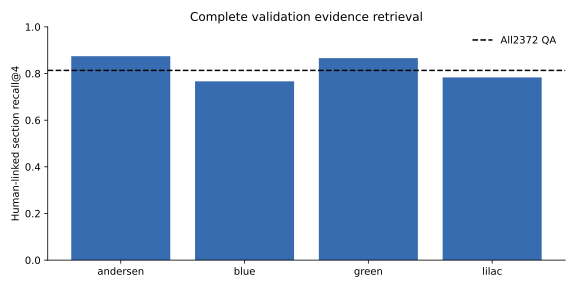

In [3]:
origins = list(retrieval["origin"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    [o.replace("-fairybook", "") for o in origins],
    [retrieval["origin"][o]["recall_at_4"] for o in origins],
    color="#386cb0",
)
ax.axhline(retrieval["recall_at_4"], linestyle="--", color="black", label="All2372 QA")
ax.set(
    ylim=(0, 1),
    ylabel="Human-linked section recall@4",
    title="Complete validation evidence retrieval",
)
ax.legend(frameon=False)
show_figure(fig, "evidence-validation-baseline")


## Context retention

Human-linked sections can be retrieved but lost when the 512-token generator
context is assembled in source order. The following measurement uses the actual
pinned T5 tokenizer and all validation QA without allocating a neural encoder.
Retaining a section ID does not establish that every supporting sentence survives.


In [4]:
retention = read_json("docs/context-retention.json")
table(
    [
        {
            k: retention[k]
            for k in (
                "n",
                "retrieved_evidence_recall",
                "retained_evidence_recall",
                "mean_input_tokens",
                "max_input_tokens",
                "source_valid",
            )
        }
    ],
    [
        "n",
        "retrieved_evidence_recall",
        "retained_evidence_recall",
        "mean_input_tokens",
        "max_input_tokens",
        "source_valid",
    ],
    "Actual pinned-tokenizer assembly; no generated answer scores",
)


n,retrieved_evidence_recall,retained_evidence_recall,mean_input_tokens,max_input_tokens,source_valid
2372,0.8134134345137718,0.5595489038785835,505.83094435075884,509,2372


## Source-family differences

These are complete-family denominators, not equal-sized convenience samples.
Lang labels describe related collections rather than independent populations.


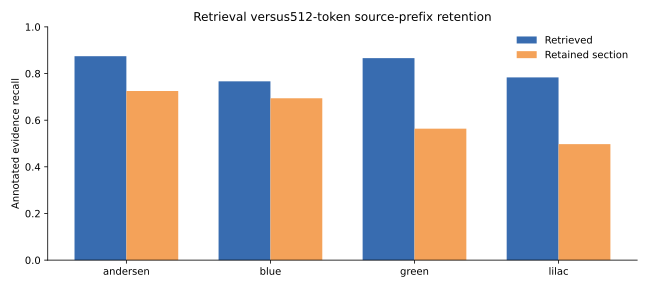

In [5]:
origins = list(retention["per_origin"])
x = np.arange(len(origins))
width = 0.36
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(
    x - width / 2,
    [retention["per_origin"][o]["retrieved_evidence_recall"] for o in origins],
    width,
    label="Retrieved",
    color="#386cb0",
)
ax.bar(
    x + width / 2,
    [retention["per_origin"][o]["retained_evidence_recall"] for o in origins],
    width,
    label="Retained section",
    color="#f4a259",
)
ax.set_xticks(x, [o.replace("-fairybook", "") for o in origins])
ax.set(
    ylim=(0, 1),
    ylabel="Annotated evidence recall",
    title="Retrieval versus512-token source-prefix retention",
)
ax.legend(frameon=False)
show_figure(fig, "context-retention")


## Actual optimization and continuation checks

The pretrained T5 and ranking-head runs use20 real training QA and2 validation QA
to verify mechanics. They do not estimate full-data QA performance. The ranking
run additionally compares every optimizer tensor and Python/NumPy/Torch RNG state.


In [6]:
g = read_json("docs/full-training-readiness.json")
r = read_json("docs/full-reranker-readiness.json")
table(
    [
        {
            "component": "T5",
            "train QA": g["train_QA"],
            "validation QA": g["validation_QA"],
            "CPU seconds": round(g["elapsed_seconds"], 2),
            "tensor replay error": g["tensor_replay_max_abs_difference"],
        },
        {
            "component": "Reranker",
            "train QA": r["train_QA"],
            "validation QA": r["validation_QA"],
            "CPU seconds": round(r["elapsed_seconds"], 2),
            "tensor replay error": r["tensor_replay_max_abs_difference"],
        },
    ],
    ["component", "train QA", "validation QA", "CPU seconds", "tensor replay error"],
    "Actual saved-state continuation receipts",
)
print(
    "Ranking equal state tensors:",
    r["equal_training_state_tensor_counts"],
    "all RNG states equal:",
    r["all_rng_states_equal"],
)


component,train QA,validation QA,CPU seconds,tensor replay error
T5,20,2,99.8,0.0
Reranker,20,2,146.27,0.0


Ranking equal state tensors: {'model': 105, 'optimizer': 315, 'rng': 1} all RNG states equal: True


## Complete model comparison

Only audited all-query selections are accepted below. Their answer curves come
from actual saved initial/epoch models, never from training loss or interpolation.
No model is selected from test outcomes.


In [7]:
selection_path = ROOT / "docs/full-generator-selection.json"
if selection_path.exists():
    selection = json.loads(selection_path.read_text(encoding="utf-8"))
    assert (
        selection["status"] == "validation_checkpoint_selection"
        and selection["validation_questions"] == 2372
    )
    curve = selection["candidates"]
    table(
        [
            {
                "epoch": r["epoch"],
                "answer F1": r["validation"]["f1"],
                "EM": r["validation"]["em"],
                "n": r["validation"]["n"],
            }
            for r in curve
        ],
        ["epoch", "answer F1", "EM", "n"],
        "Actual complete-validation checkpoint comparison",
    )
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(
        [r["epoch"] for r in curve],
        [r["validation"]["f1"] for r in curve],
        marker="o",
        label="Answer tokenF1",
    )
    ax.plot(
        [r["epoch"] for r in curve],
        [r["validation"]["em"] for r in curve],
        marker="s",
        label="Exact match",
    )
    ax.set(
        xlabel="Saved epoch",
        ylabel="Macro question score",
        title="All2372 validation QA",
    )
    ax.legend(frameon=False)
    show_figure(fig, "full-generator-validation")
else:
    print("Complete model-validation scores unavailable; no score is estimated.")


Complete model-validation scores unavailable; no score is estimated.
